# 🏠 Analyse des ventes immobilières en France (2021 – 2023)


## Objectif du notebook
Ce notebook explore les **ventes de biens immobiliers en France entre 2021 et 2023** (données DVF, *Demandes de valeurs foncières*), puis prépare un jeu de données **propre et prêt pour la modélisation**.

## Les grandes étapes
1. **Chargement** des trois fichiers annuels et fusion en un seul tableau
2. **Statistiques descriptives** (prix, surface bâtie, surface du terrain)
3. **Détection des valeurs aberrantes** (méthode IQR)
4. **Visualisations** : boxplots, nuages de points, matrice de corrélation
5. **Nettoyage** : doublons, valeurs manquantes, incohérences, types
6. **Analyse de l'évolution des prix** par année et par type de bien
7. **Préparation finale** : encodage, normalisation et export du CSV nettoyé



---
## 1️⃣ Chargement et fusion des données

On importe les bibliothèques utiles, puis on lit les trois fichiers `full_2021.csv`, `full_2022.csv` et `full_2023.csv`.
Une colonne **`annee`** est ajoutée à chacun pour savoir d'où vient chaque ligne, avant de tout rassembler dans un seul tableau `df`.

`df.info()` et `df.head()` donnent un premier aperçu : nombre de lignes, colonnes (41 au départ) et types de données.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
df_21=pd.read_csv("C:\\Users\\malek saidani\\Desktop\\python DSSD\\projet ds\\dataset\\full_2021.csv",low_memory=False,encoding='latin-1')
df_22=pd.read_csv("C:\\Users\\malek saidani\\Desktop\\python DSSD\\projet ds\\dataset\\full_2022.csv",low_memory=False,encoding='latin-1')
df_23=pd.read_csv("C:\\Users\\malek saidani\\Desktop\\python DSSD\\projet ds\\dataset\\full_2023.csv",low_memory=False,encoding='latin-1')
df_21["annee"]=2021
df_22["annee"]=2022
df_23["annee"]=2023
df=pd.concat([df_21,df_22,df_23])
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
Index: 3145725 entries, 0 to 1048574
Data columns (total 41 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   id_mutation                   object 
 1   date_mutation                 object 
 2   numero_disposition            float64
 3   nature_mutation               object 
 4   valeur_fonciere               float64
 5   adresse_numero                float64
 6   adresse_suffixe               object 
 7   adresse_nom_voie              object 
 8   adresse_code_voie             object 
 9   code_postal                   float64
 10  code_commune                  object 
 11  nom_commune                   object 
 12  code_departement              object 
 13  ancien_code_commune           float64
 14  ancien_nom_commune            object 
 15  id_parcelle                   object 
 16  ancien_id_parcelle            object 
 17  numero_volume                 object 
 18  lot1_numero                

---
## 2️⃣ Statistiques descriptives

Pour les trois variables principales — **`valeur_fonciere`** (le prix), **`surface_reelle_bati`** et **`surface_terrain`** — on calcule : moyenne, médiane, mode, étendue, variance, écart-type et asymétrie.

💡 **Comment lire les résultats :** la moyenne est nettement plus élevée que la médiane et l'asymétrie est très forte. Cela signifie que quelques ventes extrêmement chères ou très grandes tirent la moyenne vers le haut : la **médiane** représente mieux une vente « typique ».

In [ ]:
print('description prix')
print("prix moyenne :",round(df["valeur_fonciere"].mean(),2))
print("prix médiane :",df["valeur_fonciere"].median())
print("prix mode :",df["valeur_fonciere"].mode())
print("prix étendue :",round(df["valeur_fonciere"].max()-df["valeur_fonciere"].min(),2))
print("prix variance :",round(df["valeur_fonciere"].var(),2))
print("prix écart-type :",round(df["valeur_fonciere"].std(),2))
print("prix asymétrie :",round(df["valeur_fonciere"].skew(),2))
print('description surface_reelle_bati')
print("surface bâtie moyenne :",round(df["surface_reelle_bati"].mean(),2))
print("surface bâtie médiane :",df["surface_reelle_bati"].median())
print("surface bâtie mode :",df["surface_reelle_bati"].mode())
print("surface bâtie étendue :",round(df["surface_reelle_bati"].max()-df["surface_reelle_bati"].min(),2))
print("surface bâtie variance :",round(df["surface_reelle_bati"].var(),2))
print("surface bâtie écart-type :",round(df["surface_reelle_bati"].std(),2))
print("surface bâtie asymétrie  :",round(df["surface_reelle_bati"].skew(),2))
print('description surface_terrain')
print("terrain moyenne :",round(df["surface_terrain"].mean(),2))
print("terrain médiane :",df["surface_terrain"].median())
print("terrain mode :",df["surface_terrain"].mode())
print("terrain étendue :",round(df["surface_terrain"].max()-df["surface_terrain"].min(),2))
print("terrain variance :",round(df["surface_terrain"].var(),2))
print("terrain écart-type :",round(df["surface_terrain"].std(),2))
print("terrain asymétrie  :",round(df["surface_terrain"].skew(),2))

description prix
prix moyenne : 352379.24
prix médiane : 150000.0
prix mode : 0    150000.0
Name: valeur_fonciere, dtype: float64
prix étendue : 189799999.85
prix variance : 2579750930929.25
prix écart-type : 1606160.31
prix asymétrie : 26.69
description surface_reelle_bati
surface bâtie moyenne : 118.74
surface bâtie médiane : 78.0
surface bâtie mode : 0    80.0
Name: surface_reelle_bati, dtype: float64
surface bâtie étendue : 125529.0
surface bâtie variance : 528467.51
surface bâtie écart-type : 726.96
surface bâtie asymétrie  : 70.62
description surface_terrain
terrain moyenne : 2789.21
terrain médiane : 631.0
terrain mode : 0    500.0
Name: surface_terrain, dtype: float64
terrain étendue : 3805879.0
terrain variance : 135521657.45
terrain écart-type : 11641.38
terrain asymétrie  : 71.06


---
## 3️⃣ Détection des valeurs aberrantes

On utilise la **méthode IQR** : une valeur est jugée aberrante si elle est en dessous de `Q1 − 1,5 × IQR` ou au-dessus de `Q3 + 1,5 × IQR` (Q1 et Q3 sont le 1er et le 3e quartile).

Cette cellule **repère** les valeurs aberrantes pour le prix, la surface bâtie et la surface du terrain, mais elle ne les supprime pas.

In [ ]:
#Détection valeurs aberrantes valeur_fonciere
Q1=df["valeur_fonciere"].quantile(0.25)
Q2=df["valeur_fonciere"].quantile(0.5)   
Q3=df["valeur_fonciere"].quantile(0.75)
print(f"Q1={Q1},Médiane={Q2},Q3={Q3}")
IQR=Q3-Q1
print(f"IQR={IQR}")
outliers_prix=df[(df["valeur_fonciere"]<Q1-1.5*IQR)|(df["valeur_fonciere"]>Q3+1.5*IQR)]
print("Outliers :",outliers_prix)
#Détection valeurs aberrantes surface_reelle_bati
Q1=df["surface_reelle_bati"].quantile(0.25)
Q2=df["surface_reelle_bati"].quantile(0.5)   
Q3=df["surface_reelle_bati"].quantile(0.75)
print(f"Q1={Q1},Médiane={Q2},Q3={Q3}")
IQR=Q3-Q1
print(f"IQR={IQR}")
outliers_surface_reelle_bati=df[(df["surface_reelle_bati"]<Q1-1.5*IQR)|(df["surface_reelle_bati"]>Q3+1.5*IQR)]
print("Outliers :",outliers_surface_reelle_bati)
#Détection valeurs aberrantes surface_terrain
Q1=df["surface_terrain"].quantile(0.25)
Q2=df["surface_terrain"].quantile(0.5)   
Q3=df["surface_terrain"].quantile(0.75)
print(f"Q1={Q1},Médiane={Q2},Q3={Q3}")
IQR=Q3-Q1
print(f"IQR={IQR}")
outliers_surface_terrain=df[(df["surface_terrain"]<Q1-1.5*IQR)|(df["surface_terrain"]>Q3+1.5*IQR)]
print("Outliers :",outliers_surface_terrain)

Q1=60000.0,Médiane=150000.0,Q3=277100.0
IQR=217100.0
         id_mutation date_mutation  numero_disposition nature_mutation  \
138          2021-58    2021-01-19                 2.0           Vente   
139          2021-58    2021-01-19                 2.0           Vente   
140          2021-58    2021-01-19                 2.0           Vente   
141          2021-58    2021-01-19                 2.0           Vente   
767         2021-266    2021-01-28                 1.0           Vente   
...              ...           ...                 ...             ...   
3145567  2023-374394    2023-01-31                 1.0           Vente   
3145568  2023-374394    2023-01-31                 1.0           Vente   
3145569  2023-374394    2023-01-31                 1.0           Vente   
3145570  2023-374394    2023-01-31                 1.0           Vente   
3145571  2023-374394    2023-01-31                 1.0           Vente   

         valeur_fonciere  adresse_numero adresse_suffixe  

---
## 4️⃣ Visualisations des variables

### Boxplots
Un boxplot résume une variable d'un coup d'œil : la boîte contient la moitié centrale des valeurs, la ligne au milieu est la médiane, et les points au-delà des moustaches sont les valeurs aberrantes. L'axe est volontairement limité pour que les graphiques restent lisibles.

**Valeur foncière (prix)**

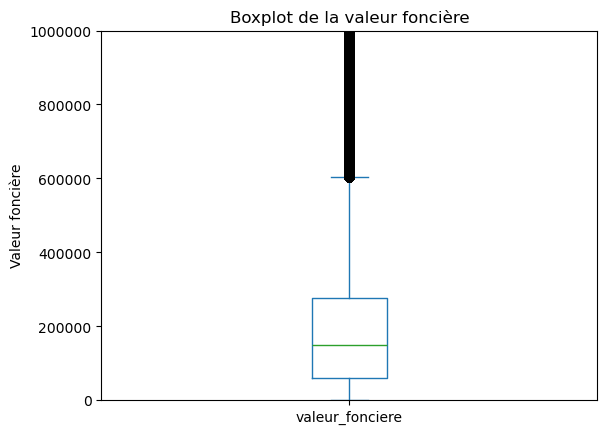

In [ ]:
#Boxplot—valeur_fonciere
ax=df["valeur_fonciere"].plot.box()
ax.set_ylim(0,1_000_000)
plt.title("Boxplot de la valeur foncière")
plt.ylabel("Valeur foncière")
plt.ticklabel_format(style='plain',axis='y')  
plt.show()

**Surface réelle bâtie (m²)**

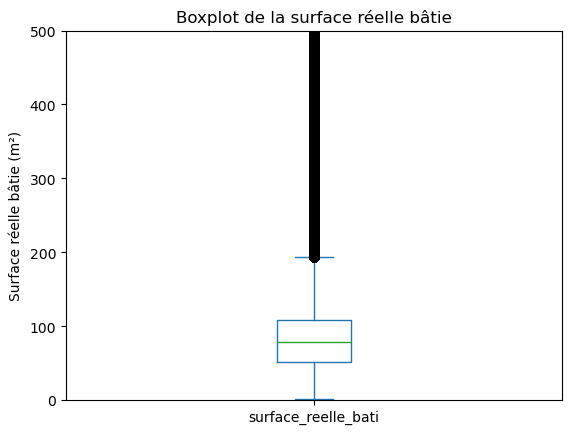

In [ ]:
# Boxplot—surface_reelle_bati
ax =df["surface_reelle_bati"].plot.box()
ax.set_ylim(0,500)
plt.title("Boxplot de la surface réelle bâtie")
plt.ylabel("Surface réelle bâtie (m²)")
plt.ticklabel_format(style='plain',axis='y')
plt.show()

**Surface du terrain (m²)**

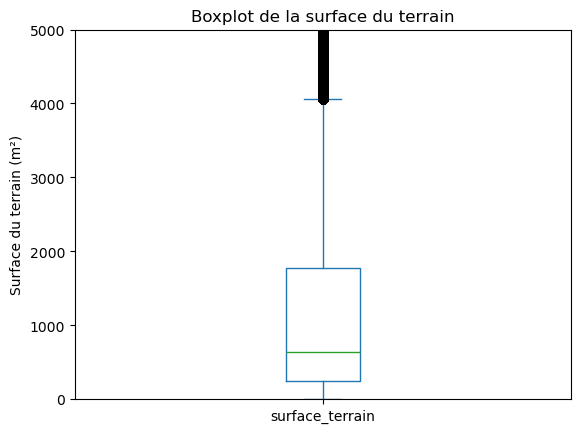

In [ ]:
# Boxplot—surface_terrain
ax=df["surface_terrain"].plot.box()
ax.set_ylim(0,5000)
plt.title("Boxplot de la surface du terrain")
plt.ylabel("Surface du terrain (m²)")
plt.ticklabel_format(style='plain',axis='y')
plt.show()

### Nuages de points (scatterplots)
Ces trois graphiques montrent si deux variables évoluent ensemble :
- prix vs surface bâtie,
- prix vs surface du terrain,
- surface bâtie vs surface du terrain.

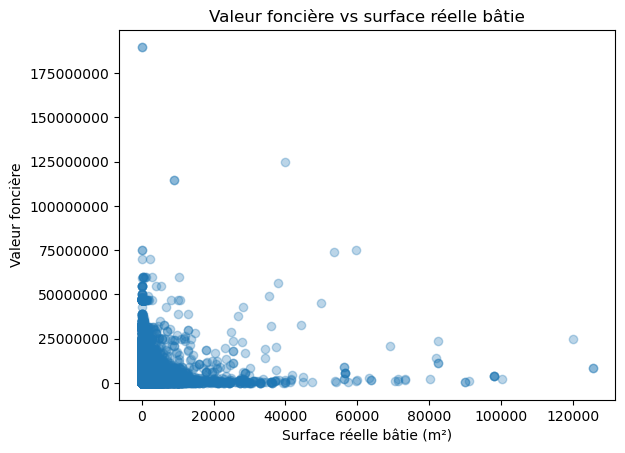

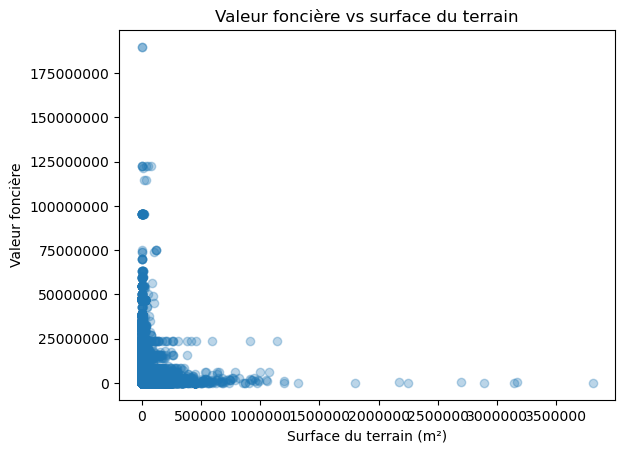

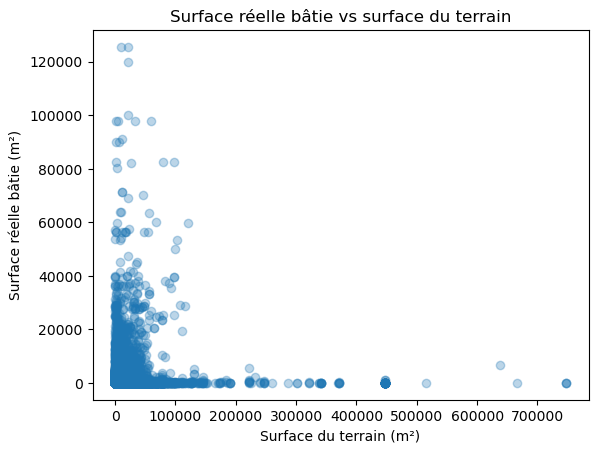

In [ ]:
#Scatterplot :valeur_fonciere vs surface_reelle_bati
plt.scatter(df["surface_reelle_bati"],df["valeur_fonciere"],alpha=0.3)
plt.title("Valeur foncière vs surface réelle bâtie")
plt.xlabel("Surface réelle bâtie (m²)")
plt.ylabel("Valeur foncière")
plt.ticklabel_format(style='plain', axis='both')
plt.show()
#Scatterplot : valeur_fonciere vs surface_terrain
plt.scatter(df["surface_terrain"],df["valeur_fonciere"],alpha=0.3)
plt.title("Valeur foncière vs surface du terrain")
plt.xlabel("Surface du terrain (m²)")
plt.ylabel("Valeur foncière")
plt.ticklabel_format(style='plain', axis='both')
plt.show()
#Scatterplot : surface_reelle_bati vs surface_terrain
plt.scatter(df["surface_terrain"],df["surface_reelle_bati"],alpha=0.3)
plt.title("Surface réelle bâtie vs surface du terrain")
plt.xlabel("Surface du terrain (m²)")
plt.ylabel("Surface réelle bâtie (m²)")
plt.ticklabel_format(style='plain',axis='both')
plt.show()

### Matrice de corrélation
La corrélation mesure le lien entre deux variables : proche de **1** = elles évoluent ensemble, proche de **0** = pas de lien linéaire, proche de **−1** = elles évoluent en sens opposé.

Ici, les valeurs sont toutes assez faibles : la surface seule n'explique pas bien le prix.

                           valeur_fonciere  surface_reelle_bati  \
valeur_fonciere                   1.000000             0.101220   
surface_reelle_bati               0.101220             1.000000   
surface_terrain                   0.044347             0.106913   
nombre_pieces_principales        -0.009673            -0.040822   

                           surface_terrain  nombre_pieces_principales  
valeur_fonciere                   0.044347                  -0.009673  
surface_reelle_bati               0.106913                  -0.040822  
surface_terrain                   1.000000                  -0.028698  
nombre_pieces_principales        -0.028698                   1.000000  


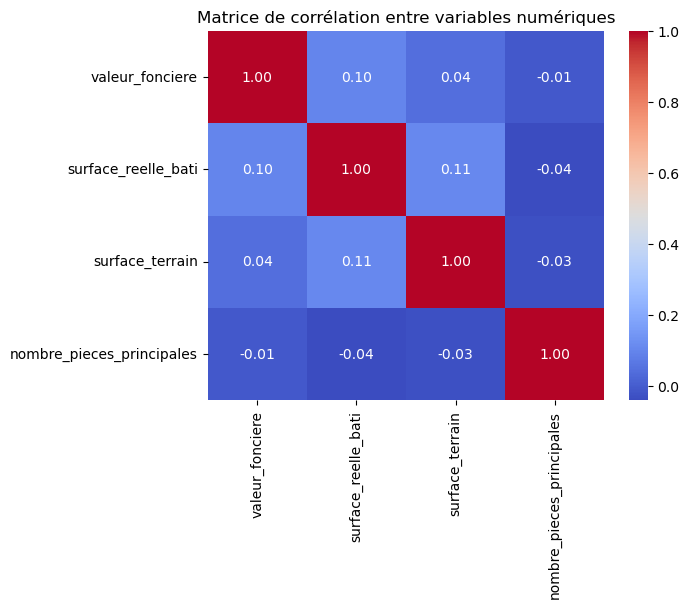

In [ ]:
#Matrice de corrélation
df_corr=df[["valeur_fonciere","surface_reelle_bati","surface_terrain","nombre_pieces_principales"]]
corr_matrix=df_corr.corr()
print(corr_matrix)
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Matrice de corrélation entre variables numériques")
plt.show()

---
## 5️⃣ Nettoyage des données

### Suppression des doublons
On compte les lignes identiques puis on les supprime, pour ne pas compter deux fois la même information.

In [ ]:
#Suppression des doublons
print("Nombre de doublons avant :",df.duplicated().sum())
df=df.drop_duplicates()
print("Nombre de doublons après :",df.duplicated().sum())

Nombre de doublons avant : 222403
Nombre de doublons après : 0


### Valeurs manquantes, incohérences, types et nouvelles variables
Cette cellule fait plusieurs choses à la suite :
- **Valeurs manquantes** : les colonnes numériques sont remplies avec la **médiane**, les colonnes catégorielles avec la **valeur la plus fréquente** (mode).
- **Incohérences** : on garde uniquement les ventes avec un prix strictement positif et des surfaces positives ou nulles.
- **Types** : `date_mutation` devient une vraie date, `annee` un entier.
- **Variable dérivée** : `prix_m2` = prix ÷ surface bâtie.
- **Premières analyses** : prix moyen par année, par type de bien, puis par année **et** type de bien.

In [ ]:
#Gestion des valeurs manquantes
num_cols=["valeur_fonciere","surface_reelle_bati","surface_terrain","nombre_pieces_principales","longitude","latitude"]
df[num_cols]=df[num_cols].fillna(df[num_cols].median())
categorie_cols=["type_local","nature_mutation","nature_culture","nature_culture_speciale","nom_commune"]
for col in categorie_cols:
    df[col]=df[col].fillna(df[col].mode()[0])
#Correction des incohérences
df=df[df["valeur_fonciere"]>0]
df=df[df["surface_reelle_bati"]>=0]
df=df[df["surface_terrain"]>=0]
#Conversion des types
df["date_mutation"]=pd.to_datetime(df["date_mutation"],errors="coerce")
df["annee"]=df["annee"].astype(int)
#Variable dérivée
df["prix_m2"]=df["valeur_fonciere"]/df["surface_reelle_bati"]
#Prix moyen par année
prix_par_annee=df.groupby("annee")["valeur_fonciere"].mean()
print(prix_par_annee)
#Prix moyen par type de bien
prix_par_type=df.groupby("type_local")["valeur_fonciere"].mean()
print(prix_par_type)
# Prix moyen par année ET type de bien
prix_annee_type=df.groupby(["annee", "type_local"])["valeur_fonciere"].mean()
print(prix_annee_type)

annee
2021    296356.223380
2022    328503.571956
2023    323739.920027
Name: valeur_fonciere, dtype: float64
type_local
Appartement                                 271584.487362
Dépendance                                  305561.292364
Local industriel. commercial ou assimilé    906662.422518
Maison                                      284750.586617
Name: valeur_fonciere, dtype: float64
annee  type_local                              
2021   Appartement                                 2.605064e+05
       Dépendance                                  2.884369e+05
       Local industriel. commercial ou assimilé    7.153207e+05
       Maison                                      2.825978e+05
2022   Appartement                                 2.814437e+05
       Dépendance                                  3.233447e+05
       Local industriel. commercial ou assimilé    8.910033e+05
       Maison                                      2.835306e+05
2023   Appartement                               

---
## 6️⃣ Évolution des prix

### Prix moyen par année
La courbe montre comment le prix moyen d'une vente a évolué de 2021 à 2023.

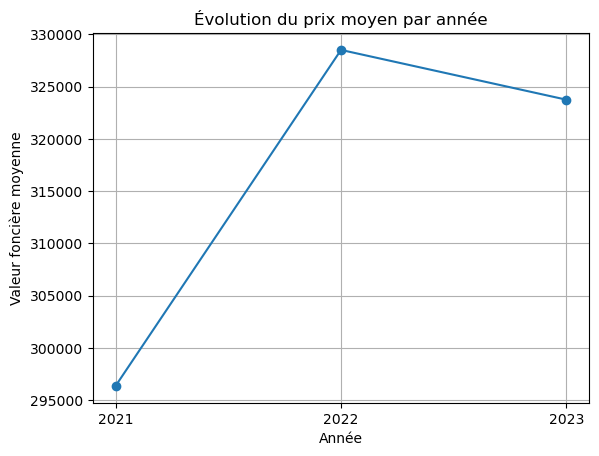

In [ ]:
#visualisation évolution du prix moyen par annee
prix_par_annee.plot(marker='o')
plt.title("Évolution du prix moyen par année")
plt.xlabel("Année")
plt.ylabel("Valeur foncière moyenne")
plt.xticks(prix_par_annee.index,prix_par_annee.index.astype(int))
plt.ticklabel_format(style='plain',axis='y')
plt.grid(True)
plt.show()

### Prix moyen par année selon le type de bien
Même idée, mais une courbe par type de bien : appartement, maison, dépendance, local industriel ou commercial.

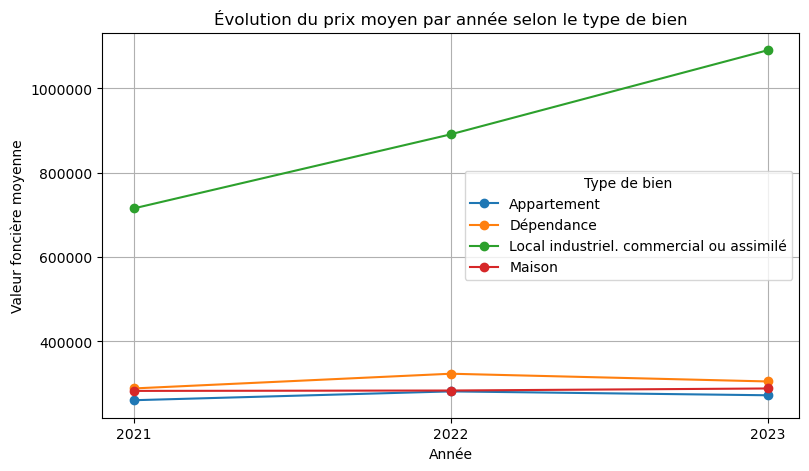

In [ ]:
prix_annee_type.unstack().plot(figsize=(9,5),marker='o')
plt.title("Évolution du prix moyen par année selon le type de bien")
plt.xlabel("Année")
plt.ylabel("Valeur foncière moyenne")
plt.xticks(prix_annee_type.index.levels[0],prix_annee_type.index.levels[0].astype(int))
plt.ticklabel_format(style='plain',axis='y')
plt.legend(title="Type de bien")
plt.grid(True)
plt.show()

---
## 7️⃣ Préparation finale et export

- **Encodage** : la colonne `type_local` (du texte) est transformée en colonnes 0/1 (*one-hot encoding*), que les modèles de machine learning savent lire.
- **Normalisation** : le prix et les deux surfaces sont mis à l'échelle avec **`RobustScaler`**, une méthode peu sensible aux valeurs extrêmes.
- **Vérification finale** : structure, valeurs manquantes et statistiques du jeu de données.
- **Export** : le résultat est enregistré dans `dataset_immobilier_2021_2023_nettoye_final.csv`.

In [ ]:
#Encodage des variables catégorielles
df=pd.get_dummies(df,columns=["type_local"],prefix="type",dtype=int)
#Normilisation
scaler=RobustScaler()
df[["valeur_fonciere","surface_reelle_bati","surface_terrain"]]=scaler.fit_transform(df[["valeur_fonciere","surface_reelle_bati","surface_terrain"]])
#vérification finale
print(df.info())
print(df.isna().sum())
print(df.describe())
#export final
df.to_csv("C:\\Users\\malek saidani\\Desktop\\python DSSD\\projet ds\\dataset\\dataset_immobilier_2021_2023_nettoye_final.csv",index=False,encoding="latin-1")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3145725 entries, 0 to 3145724
Data columns (total 44 columns):
 #   Column                                         Dtype  
---  ------                                         -----  
 0   id_mutation                                    object 
 1   date_mutation                                  object 
 2   numero_disposition                             float64
 3   nature_mutation                                object 
 4   valeur_fonciere                                float64
 5   adresse_numero                                 float64
 6   adresse_suffixe                                object 
 7   adresse_nom_voie                               object 
 8   adresse_code_voie                              object 
 9   code_postal                                    float64
 10  code_commune                                   object 
 11  nom_commune                                    object 
 12  code_departement                          

---
## ✅ Conclusion

Les données brutes (3 fichiers annuels) ont été **fusionnées, explorées, nettoyées et préparées**. Le fichier final peut maintenant servir à :
- construire un modèle de **prédiction du prix** d'un bien,
- approfondir l'analyse par région, commune ou type de bien.

Source des données : [Real Estate Dataset sur Kaggle](https://www.kaggle.com/datasets/nechbamohammed/real-estate-dataset)